<a href="https://colab.research.google.com/github/yamenetoo/Fast-Face-tracking/blob/main/notebooks/colab_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# fastfacetrack: run the simulation

All the code lives in the package. This notebook only installs it, runs the simulation and shows the results (about 10 minutes on CPU; choose **Runtime → Run all**).

### 1. Install

In [1]:
%pip install -q git+https://github.com/yamenetoo/Fast-Face-tracking.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


### 2. Run the simulation

In [2]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
import fastfacetrack as fft

cfg = fft.ExperimentConfig(out_dir="results")      # change settings here, e.g. n_test_videos=5
res = fft.run_experiment(cfg)

identities: 9 usable | target=person_004 | seen others=['person_005', 'person_002', 'person_006', 'person_003', 'person_008'] | unseen=['person_007', 'person_000', 'person_001']
  clip person_004: 120 faces extracted
  clip person_005: 120 faces extracted
  clip person_002: 120 faces extracted
  clip person_006: 120 faces extracted
  clip person_003: 120 faces extracted
  clip person_008: 120 faces extracted
clustering (6 clusters): purity=1.000, silhouette=0.417
training done:
 model  train_seconds  val_accuracy   val_f1
logreg           0.18      1.000000 1.000000
    rf           1.09      1.000000 1.000000
  tree           0.14      0.993333 0.983051
   ann           9.43      1.000000 1.000000
   cnn          26.43      1.000000 1.000000
test video 0: actors=['person_003', 'person_008', 'person_001', 'person_007']
test video 1: actors=['person_002', 'person_006', 'person_007', 'person_000']
test video 2: actors=['person_002', 'person_003', 'person_007', 'person_000']
done in 476.2

### 3. Results

In [3]:
from IPython.display import display, Image
print("Training (validation on held-out frame blocks)")
display(res["train_report"].round(3))
print("Test videos: mean over videos, per detector and model")
display(res["aggregate"].round(3))

Training (validation on held-out frame blocks)


,model,kind,parameters,train_seconds,n_train,n_val,val_accuracy,val_precision,val_recall,val_f1
0,logreg,classical,NaN,0.18,570,150,1.000,1.0,1.000,1.000
1,rf,classical,NaN,1.09,570,150,1.000,1.0,1.000,1.000
2,tree,classical,NaN,0.14,570,150,0.993,1.0,0.967,0.983
3,ann,deep,213249.0,9.43,570,150,1.000,1.0,1.000,1.000
4,cnn,deep,25409.0,26.43,570,150,1.000,1.0,1.000,1.000


Test videos: mean over videos, per detector and model


video_mean  video_std  frames_mean  frames_std  \
detector            model                                                    
ultralight-rfb-320  logreg         1.0        1.0        400.0         0.0   
                    rf             1.0        1.0        400.0         0.0   
                    tree           1.0        1.0        400.0         0.0   
                    ann            1.0        1.0        400.0         0.0   
                    cnn            1.0        1.0        400.0         0.0   
ultralight-slim-320 logreg         1.0        1.0        400.0         0.0   
                    rf             1.0        1.0        400.0         0.0   
                    tree           1.0        1.0        400.0         0.0   
                    ann            1.0        1.0        400.0         0.0   
                    cnn            1.0        1.0        400.0         0.0   
haar                logreg         1.0        1.0        400.0         0.0   
                    rf             1.0        1.0        400.0         0.0   
                    tree           1.0        1.0        400.0         0.0   
                    ann            1.0        1.0        400.0         0.0   
                    cnn            1.0        1.0        400.0         0.0   

                            detect_ms_mean  detect_ms_std  classify_ms_mean  \
detector            model                                                     
ultralight-rfb-320  logreg          13.695          0.451             0.974   
                    rf              13.695          0.451            12.428   
                    tree            13.695          0.451             0.312   
                    ann             13.695          0.451             6.149   
                    cnn             13.695          0.451            12.883   
ultralight-slim-320 logreg          10.397          0.637             0.817   
                    rf              10.397          0.637            13.804   
                    tree            10.397          0.637             0.329   
                    ann             10.397          0.637             6.021   
                    cnn             10.397          0.637            11.443   
haar                logreg         100.872          7.050             0.937   
                    rf             100.872          7.050            12.873   
                    tree           100.872          7.050             0.275   
                    ann            100.872          7.050             6.132   
                    cnn            100.872          7.050            12.136   

                            classify_ms_std  total_ms_mean  total_ms_std  ...  \
detector            model                                                 ...   
ultralight-rfb-320  logreg            0.192         14.669         0.271  ...   
                    rf                0.094         26.122         0.447  ...   
                    tree              0.030         14.007         0.452  ...   
                    ann               0.648         19.843         0.888  ...   
                    cnn               0.443         26.578         0.884  ...   
ultralight-slim-320 logreg            0.022         11.215         0.622  ...   
                    rf                1.712         24.202         1.107  ...   
                    tree              0.076         10.726         0.605  ...   
                    ann               0.555         16.419         1.129  ...   
                    cnn               0.847         21.840         1.473  ...   
haar                logreg            0.231        101.809         7.244  ...   
                    rf                1.005        113.745         7.985  ...   
                    tree              0.003        101.147         7.050  ...   
                    ann               0.275        107.004         6.785  ...   
                    cnn               0.910        113.008   

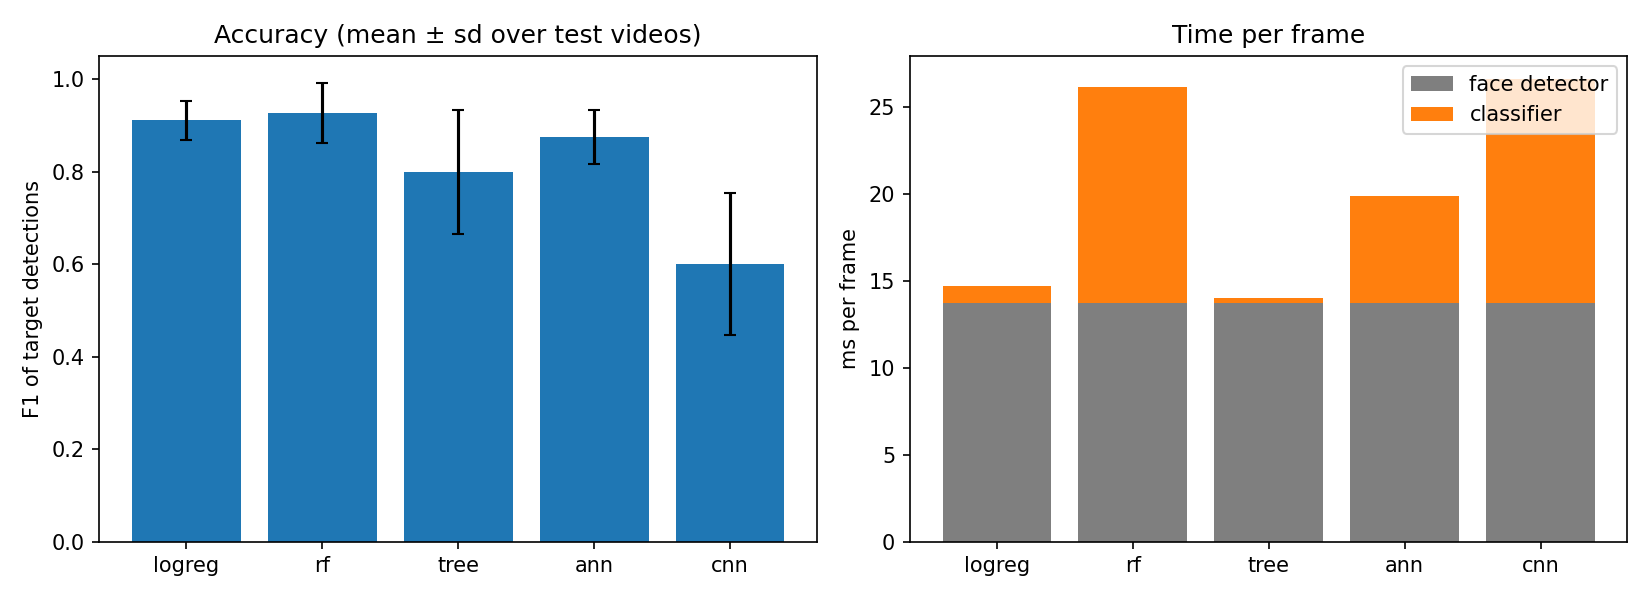

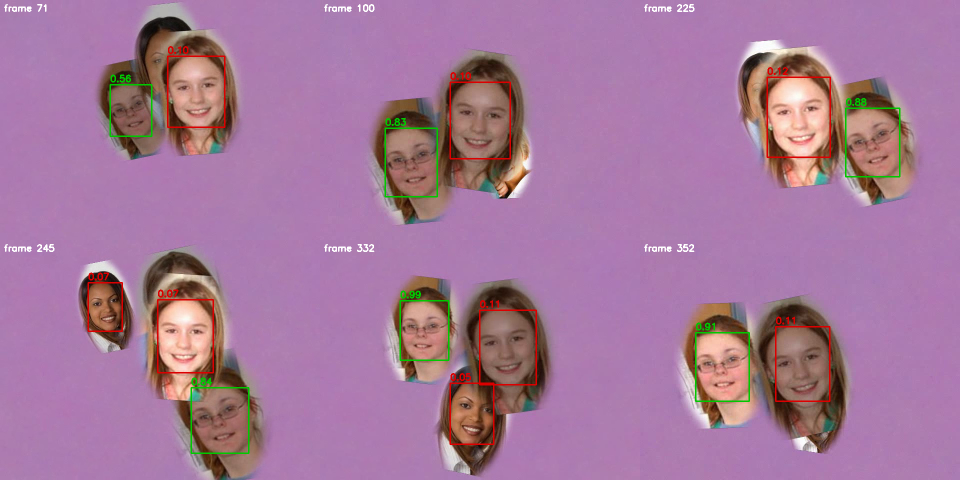

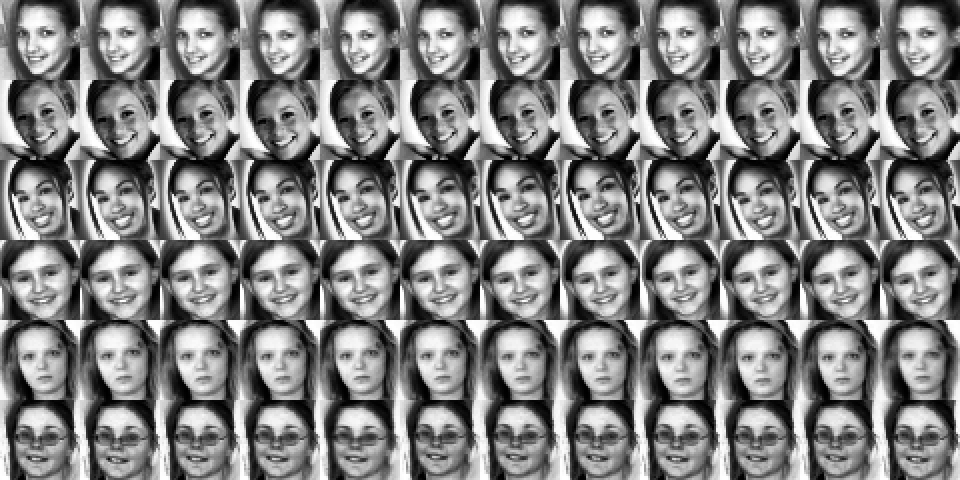

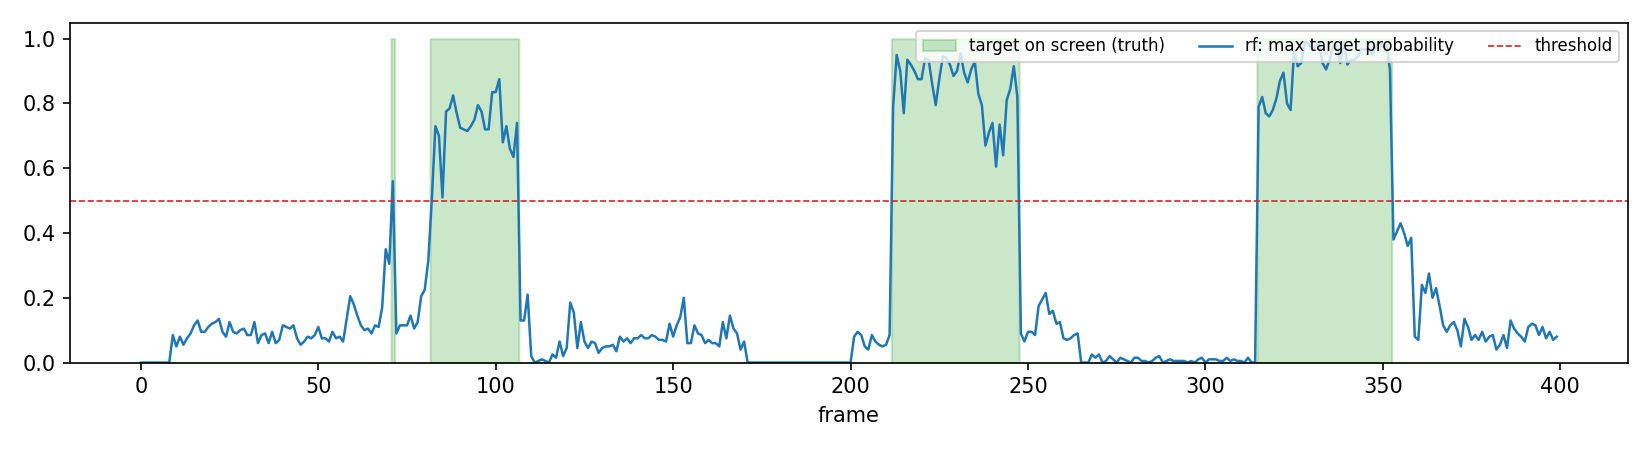

In [4]:
for name in ["model_comparison", "annotated_frames", "cluster_montage", "timeline_rf"]:
    display(Image(f"results/figures/{name}.png"))

Everything is saved in `results/` (tables, figures, trained models, `summary.json`). To use your own videos see the README: `fft.extract_faces`, `fft.train_models`, `fft.evaluate_video`.

### 4. Moving objects: SWIFT-MO (statistical detection, segmentation, classification)

A second, independent experiment (about 1 minute on CPU). It needs no trained detector: every sub-window of each frame is scored in O(1) from integral images, the alarm threshold is calibrated on object-free frames, and the class of each tracked object is decided over time by a sequential probability ratio test.

If the package was installed before this section existed, rerun the install cell first (Runtime → Restart session) to get the new version.

In [ ]:
res_mv = fft.run_moving_experiment("results/moving")          # also prints the summary

In [ ]:
import cv2, numpy as np
from IPython.display import display, Image
from fastfacetrack.moving import annotate_moving

idx = [10, 60, 120, 180]
tiles = [annotate_moving(res_mv["frames"][i], res_mv["truths"][i], res_mv["detections"][i]) for i in idx]
ok, png = cv2.imencode(".png", np.hstack(tiles))
display(Image(png.tobytes()))          # green = truth, red = detection with its SPRT class